# core

> BFrame

In [ ]:
#| default_exp core

In [ ]:
#| hide
from nbdev.showdoc import *

In [ ]:
#| export
from fastcore.all import *
from basedpl import *
from math import inf

# BFrame

In [ ]:
#| export
@patch
def _classify(self:Array): 
    self.__class__ = FunctionArray if self._inner.holds_functions else BFrame

class BFrame(Array): ...

In [ ]:
test_frame = BFrame(dict(col=[1,2,3]))
test_frame

┌→────────────┐
│ col:┌→────┐ │
│     │1 2 3│ │
│     └ₓ────┘ │
└∊────────────┘

In [ ]:
test_eq(BFrame, type(test_frame))

## Reading and writing

### CSV

In [ ]:
#| export
@patch(cls_method=True)
def read_csv(cls:BFrame, path, **kwargs): return cls(csv(nget(path, **kwargs)))

In [ ]:
bf = BFrame.read_csv("../data/toy.csv", encoding="UTF-8")
bf.df.head(3)

,Number,City,Gender,Age,Income,Illness
0,1,Dallas,Male,41,40367.0,No
1,2,Dallas,Male,54,45084.0,No
2,3,Dallas,Male,42,52483.0,No


In [ ]:
#| export
@patch
def save_csv(self:BFrame, path): return nput(path, csv.undo(self))

In [ ]:
# bf.save_csv("../data/save_test.csv");

## Selection

In [ ]:
#| export
@patch
def take(self:BFrame, n:int): return take.each(n, self)

In [ ]:
head = bf.take(100)
head.take(2).df

,Number,City,Gender,Age,Income,Illness
0,1,Dallas,Male,41,40367.0,No
1,2,Dallas,Male,54,45084.0,No


In [ ]:
#| export
@patch
def head(self:BFrame, n=5): return self.take(n)

In [ ]:
bf.head().df

,Number,City,Gender,Age,Income,Illness
0,1,Dallas,Male,41,40367.0,No
1,2,Dallas,Male,54,45084.0,No
2,3,Dallas,Male,42,52483.0,No
3,4,Dallas,Male,40,40941.0,No
4,5,Dallas,Male,46,50289.0,No


In [ ]:
#| export
@patch
def tail(self:BFrame, n=5): return self.take(-n)

In [ ]:
bf.tail().df

,Number,City,Gender,Age,Income,Illness
0,149996,Austin,Male,48,93669.0,No
1,149997,Austin,Male,25,96748.0,No
2,149998,Austin,Male,26,111885.0,No
3,149999,Austin,Male,25,111878.0,No
4,150000,Austin,Female,37,87251.0,No


## Agg

In [ ]:
MEAN = add.reduce_first / tally
MEAN(bf.head(100)["Income"])

44362.88

## Groupby

In [ ]:
#| export
@patch
def group_fn(self:BFrame, aggs): 
    fanout = fn('{f←↑⍺⋄f ⍵}').rank([0, inf])
    return right.after(fanout.left(aggs)).key

In [ ]:
RMSE = MEAN.under(square)
fn_dict=dict(mean=MEAN, rmse=RMSE)
fn_dict

{'mean': +⌿÷≢, 'rmse': (+⌿÷≢)@⊼}

In [ ]:
bf.group_fn(fn_dict)

⊢↢(["mean":+⌿÷≢ "rmse":(+⌿÷≢)@⊼]↣({f←↑⍺⋄f ⍵}⍤[0 ∞]))⌸

In [ ]:
#| export
@patch
def groupby(self:BFrame, by, cols, **aggs):
    def matrix(cols): return transpose(mix(self[listify(cols)]))
    return self.group_fn(aggs)(matrix(by), matrix(cols))

In [ ]:
head.groupby("Gender", "Income", rmse=RMSE)

┌→───────────────┐
↓0⌷              │
↓          Income│
│rmse 49632.10639│
│                │
│1⌷              │
│          Income│
│rmse 40738.65853│
└~───────────────┘

In [ ]:
type(head.groupby("Gender", "Income", rmse=RMSE))

__main__.BFrame

In [ ]:
head.groupby("Gender", ["Age", "Income"], mean=MEAN, rmse=RMSE)

┌→───────────────────────────┐
↓0⌷                          │
↓             Age      Income│
│mean 44.57407407 48301.42593│
│rmse 45.66970793 49632.10639│
│                            │
│1⌷                          │
│             Age      Income│
│mean 45.30434783 39739.36957│
│rmse 46.73468128 40738.65853│
└~───────────────────────────┘

## Rolling

## Viz

In [ ]:
#| export
@patch
def plot(self:BFrame, **kwargs): return plot(self, **kwargs)

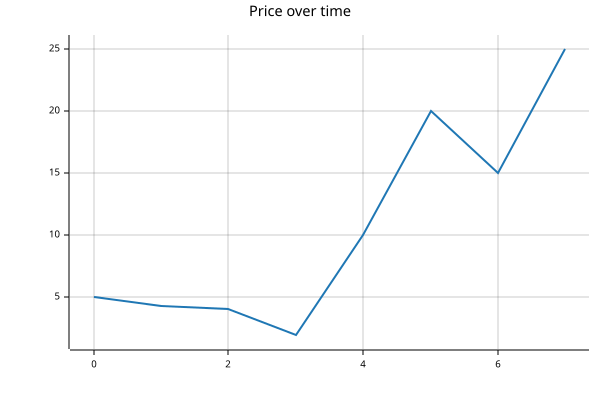

In [ ]:
BFrame(dict(price=[5,4.3,4.1,2,10,20,15,25])).plot(mark="line", title="Price over time")

In [ ]:
#| export
@patch
def hist_input(self:BFrame, n:int):
    lo,hi = Array([minimum.reduce_first, maximum.reduce_first])(self)
    w = (hi-lo)/n
    starts = lo+w*iota(n)
    return Array(dict(x=starts+w/2,
        count=take(n, where.undo(interval_index(starts[1:], self)))))

In [ ]:
income = head["Income"]
income.hist_input(5).df

,x,count
0,21417.9,6
1,31917.7,21
2,42417.5,27
3,52917.3,36
4,63417.1,10


In [ ]:
#| export
@patch
def hist(self:BFrame, n=50, **kwargs): return plot(self.hist_input(n), mark="bar", **kwargs)

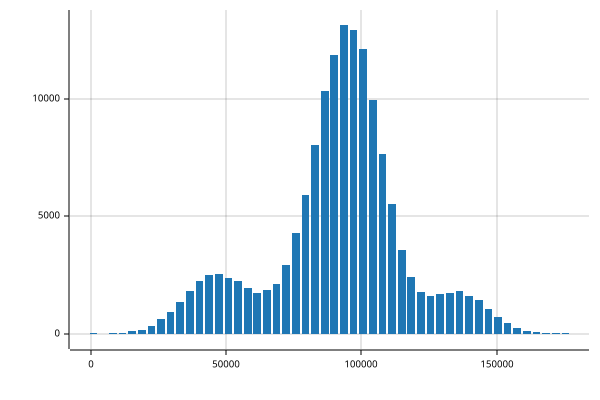

In [ ]:
bf["Income"].hist()

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()